# Can the institutes compare four independent representations?

We know how to fit one table. Now imagine that each institute follows that approach for each modality separately. **We will fit four independent six-factor Gaussian MOFA-FLEX models**: Asteron RNA, Asteron protein, Borealis RNA and Borealis protein. No fit shares its sample coordinates or weights with another.

We will inspect what each representation captures before asking whether their patterns correspond. This is the difficulty that motivates integration in the next two notebooks.

**Predict:** will factor 1 mean inflammation in every fit? Can we correlate sample scores for inhabitants who live on different planets?

### Read the same observations again in a fresh notebook

`course_utils` supplies the data readers, plotting helpers, comparison helpers and shared settings. `load_experiment()` reads the four saved AnnData tables into `data[planet][view]`; it performs no fitting or truth-based adjustment. We will now use all four tables, each in a separate fit.

In [2]:
from pathlib import Path
import sys, time
HERE = Path.cwd() if Path('course_utils.py').exists() else Path.cwd() / 'notebooks'
sys.path.insert(0, str(HERE))
from course_utils import *
from IPython.display import display
from sklearn.decomposition import PCA
# Observations only. Ground truth is loaded explicitly for later diagnostics.
data = load_experiment()

### Keep the fitting settings visible

We import MOFA-FLEX and set one PyTorch CPU thread. The printed `FIT` dictionary supplies the same Gaussian likelihood, seed 42, learning rate .02, epoch cap and stopping controls to all **four independent fits**. `**FIT` in a fit call expands this dictionary into keyword arguments. Reusing numerical settings does not make independently fitted factor columns correspond.

In [3]:
import mofaflex as mf
import torch
torch.set_num_threads(1)
print('MOFA-FLEX', mf.__version__)
print('Training settings:', FIT)

/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
/Users/flores/Dropbox/EBI/Teaching/VIB/MOFA_training/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.


Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.

MOFA-FLEX 0.2.0rc2.dev16+g2710274b7
Training settings: {'device': 'cpu', 'likelihoods': 'Normal', 'seed': 42, 'save_path': False, 'max_epochs': 1200, 'lr': 0.02, 'early_stopper_patience': 250, 'batch_size': 0, 'subset_var': None, 'plot_data_overview': False, 'update_every': -1, 'scale_elbo': True}


## Check what can be matched across the four tables

`schematic('separate')` draws four dimension-labelled models with different score and weight matrices. It is a picture of the intended analysis, not its output. The assertions then check two different relationships: the planets have disjoint sample identifiers, while RNA features match RNA features across planets and protein features match protein features across planets.

Within a planet, RNA and protein measure the same inhabitants, so their independently learned sample scores can be compared by identifier. Across planets, we can compare weights on matching features within a modality, but cannot pair the sample scores. RNA and protein feature spaces are different.

Each upcoming Gaussian fit centres and block-scales its own table. Consequently score scales and factor indices belong to their own fit. The printed dimensions remind us exactly which observations each model will receive.

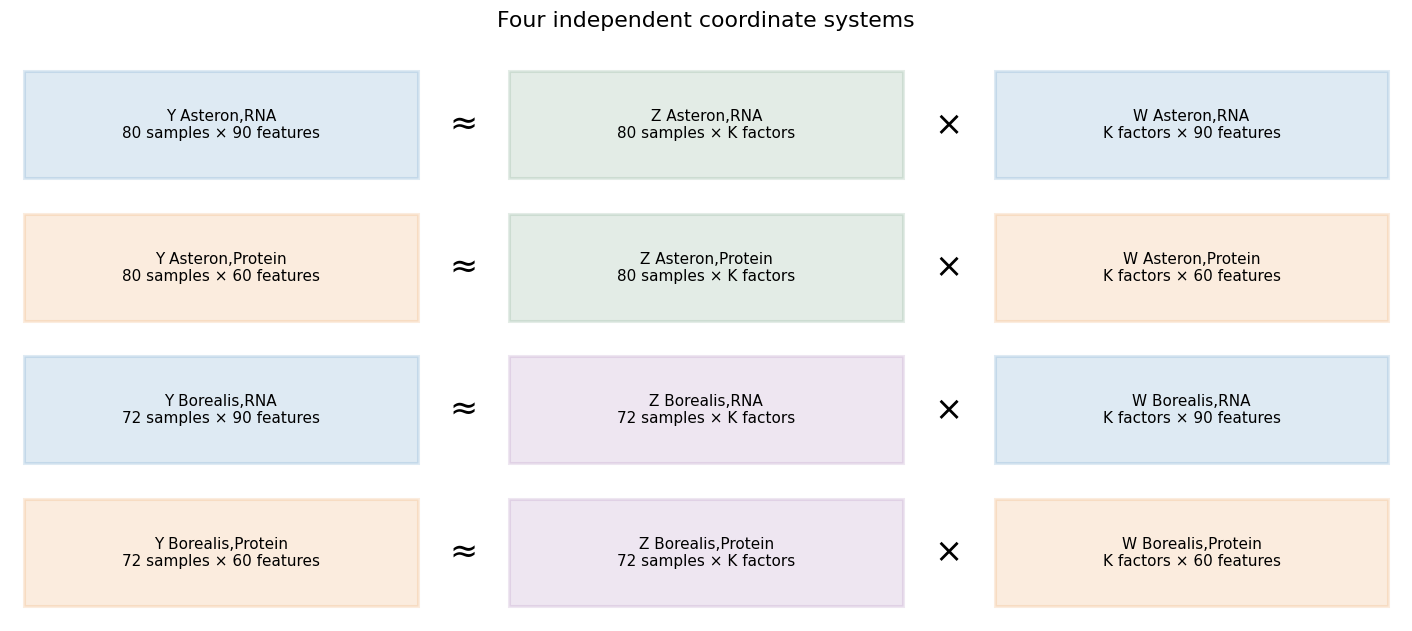

,planet,view,samples,features
0,Asteron,RNA,80,90
1,Asteron,Protein,80,60
2,Borealis,RNA,72,90
3,Borealis,Protein,72,60


In [4]:
schematic('separate')
assert set(data['Asteron']['RNA'].obs_names).isdisjoint(data['Borealis']['RNA'].obs_names)
for v in SPEC['features']:
    assert data['Asteron'][v].var_names.equals(data['Borealis'][v].var_names)
display(pd.DataFrame([dict(planet=g, view=v, samples=a.n_obs, features=a.n_vars)
                      for g, views in data.items() for v, a in views.items()]))

## Inspect the inputs before fitting the four models

The next two cells display `SPEC` and `data`. `SPEC` gives the original experiment's counts and noise levels; `data` shows the four AnnData containers we have loaded. Neither cell trains a model or exposes teacher scores. Use them to name the planet, modality, sample count and feature count of each upcoming fit.

We will use Normal factor priors and SpikeSlab weight priors, as explored in notebook 03. This notebook uses **PCA initialisation**, whereas the prior experiment used random initialisation. That is a fitting choice, not evidence that the true biological programs are PCs.

**Predict:** RNA has no direct measurement of the protein-only process. Could finite-sample chance nevertheless produce an association between an RNA factor and that process?

In [5]:
 SPEC

{'seed': 2026,
 'samples': {'Asteron': 80, 'Borealis': 72},
 'features': {'RNA': 90, 'Protein': 60},
 'diseased': {'Asteron': 40, 'Borealis': 48},
 'noise_sd': {'RNA': 0.55, 'Protein': 1.1},
 'n_processes': 6}

### Locate each model's observations

Read `data` as a dictionary of planets containing dictionaries of views. Each AnnData summary reports inhabitants × features. These are the inputs to the four fits; the following loop will take one entry at a time, rather than concatenate planets or modalities.

In [6]:
data

{'Asteron': {'RNA': AnnData object with n_obs × n_vars = 80 × 90
      obs: 'planet', 'disease', 'batch'
      layers: None (.X),
  'Protein': AnnData object with n_obs × n_vars = 80 × 60
      obs: 'planet', 'disease', 'batch'
      layers: None (.X)},
 'Borealis': {'RNA': AnnData object with n_obs × n_vars = 72 × 90
      obs: 'planet', 'disease', 'batch'
      layers: None (.X),
  'Protein': AnnData object with n_obs × n_vars = 72 × 60
      obs: 'planet', 'disease', 'batch'
      layers: None (.X)}}

## Fit one model per planet–view table

The nested loop constructs a **new six-factor Gaussian model** for each of the four tables, with Normal factor priors, SpikeSlab weights and PCA initialisation. `make_mudata({v: data[g][v]})` copies and checks that single view in the container expected by our fitting workflow; it does not combine it with any other table. Inference begins at `.fit(...)`.

The returned factors form a sample × six table for that fit; `.loc[...]` restores the corresponding inhabitant order. The weights form a feature × six table. The `(planet, view)` keys keep the four results separate. `export_fit` writes their scores, weights, whole-model R² and loss arrays under distinct `results/independent_.../` folders. Later notebooks will read these exact summaries rather than silently replacing the independent fits.

In [7]:
models, scores, weights = {}, {}, {}
for g in SPEC['samples']:
    for v in SPEC['features']:
        model = mf.terms.MofaFlex(n_factors=6, factor_prior='Normal',
                                  weight_prior='SpikeSlab', init_factors='pca')
        model.fit(make_mudata({v: data[g][v]}), **FIT)
        models[g, v] = model
        scores[g, v] = next(iter(model.get_factors().values())).loc[data[g][v].obs_names]
        weights[g, v] = model.get_weights()[v]
        export_fit(model, f'independent_{g}_{v}')

INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


INFO	Training converged after 1010 epochs.


INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


INFO	Training converged after 842 epochs.


INFO	Initializing factors using 'pca' method...


INFO 	 Guessed max_plate_nesting = 2


### Look at each local representation on its own terms

These panels show the **four independent fits**. The score plots display each fit's first two returned factors, colouring by disease only after training. Equal axis positions across panels do not imply equal biological directions.

For each fit, `weights_plot(w.iloc[:, :3], ...)` selects the 18 features with the largest absolute weight across its first three factor columns, then displays their signed weights. Feature selections can differ between panels. These are selected weight patterns within each fit, not an automatic cross-model correspondence.

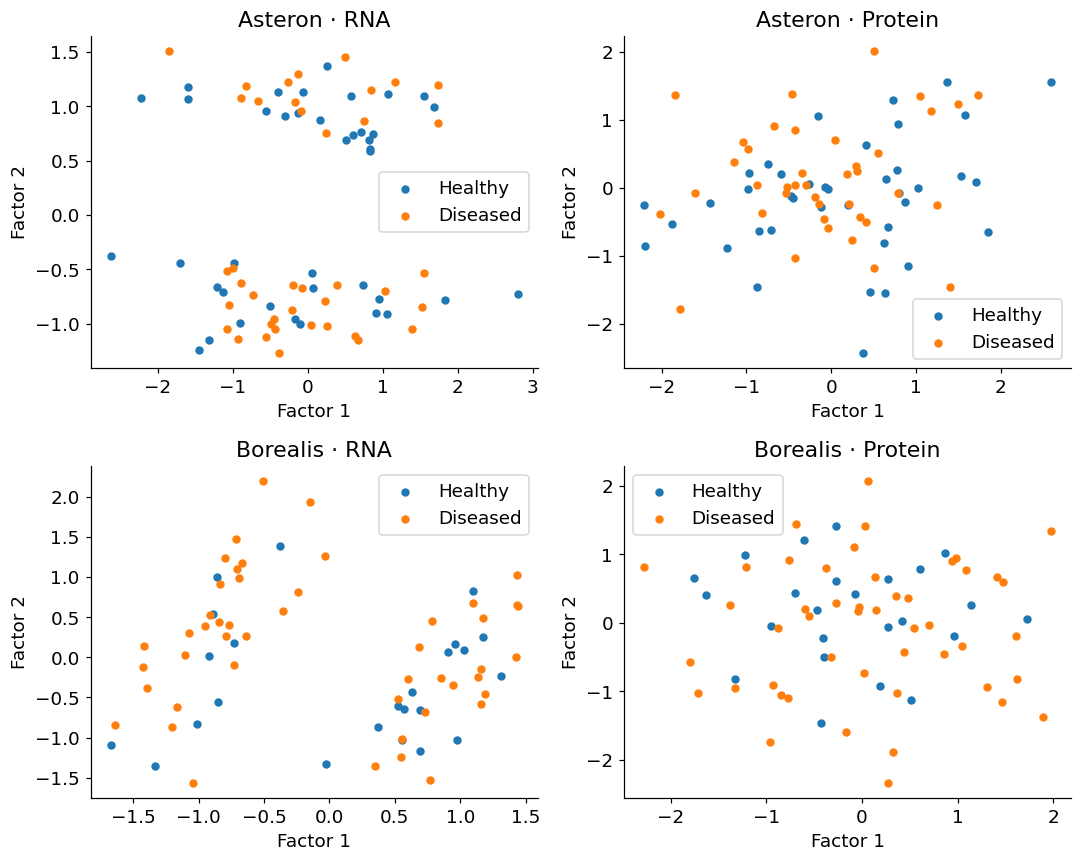

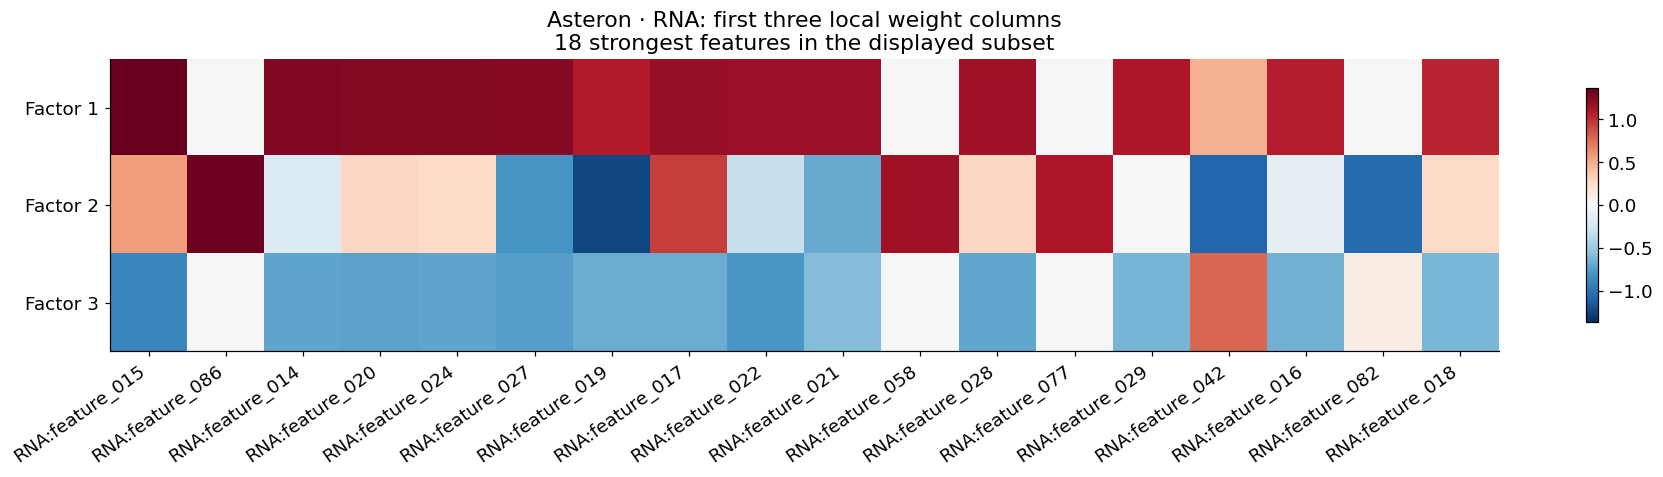

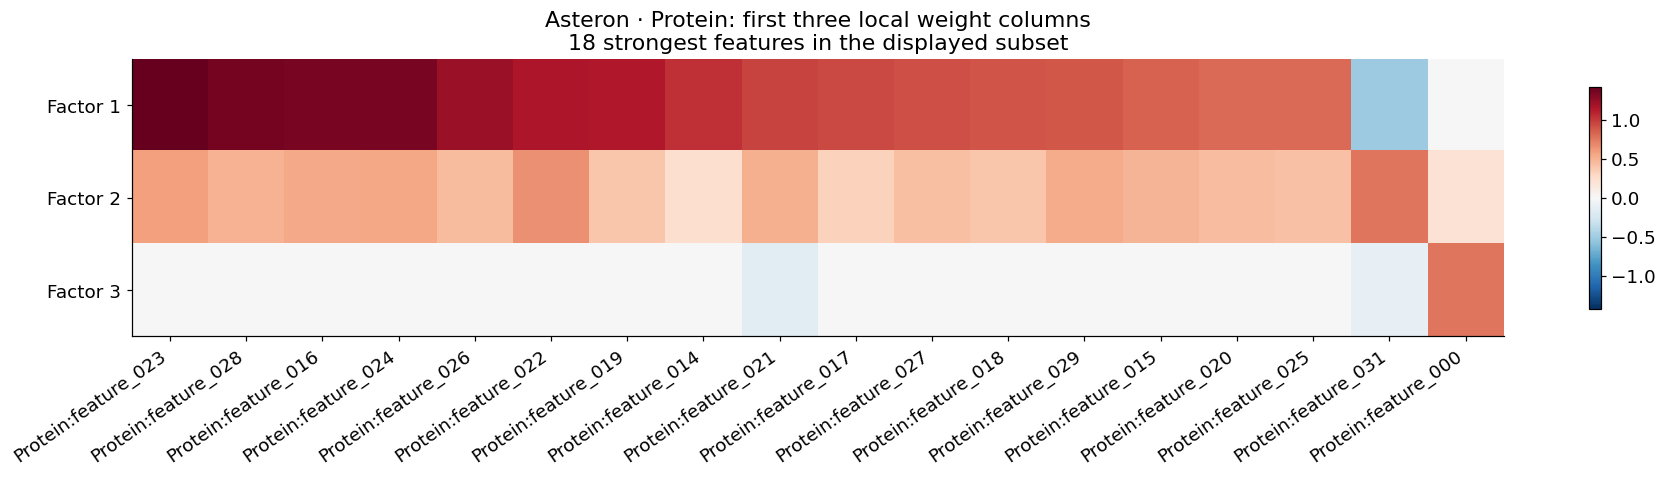

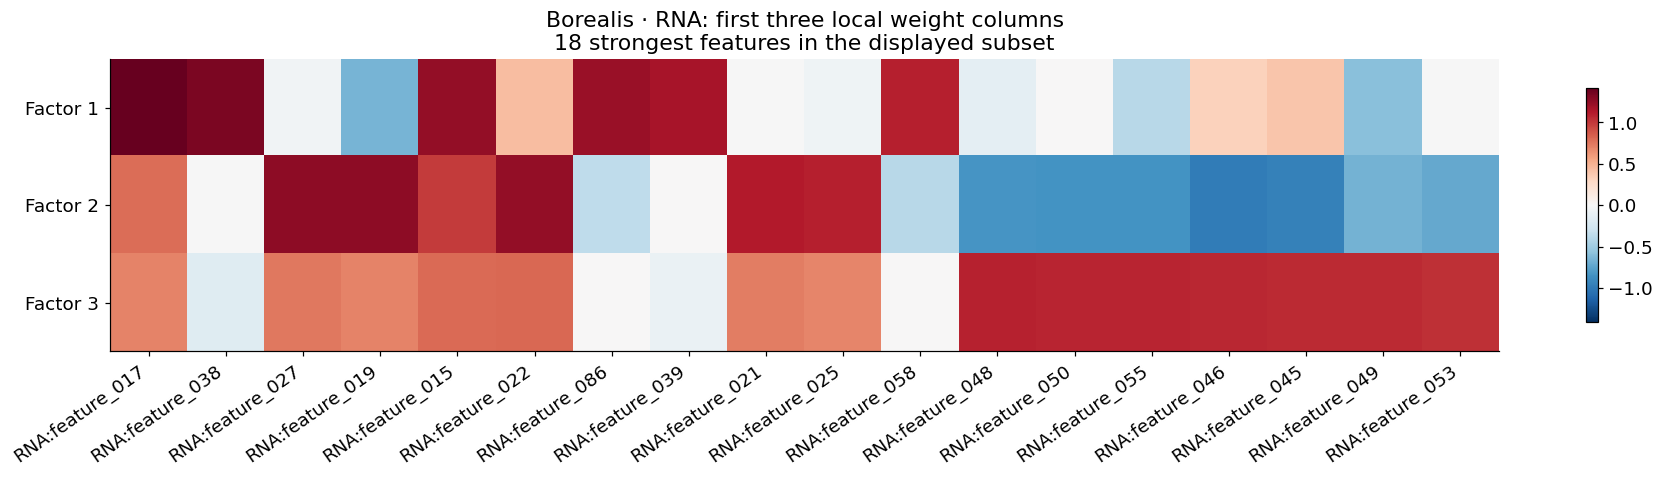

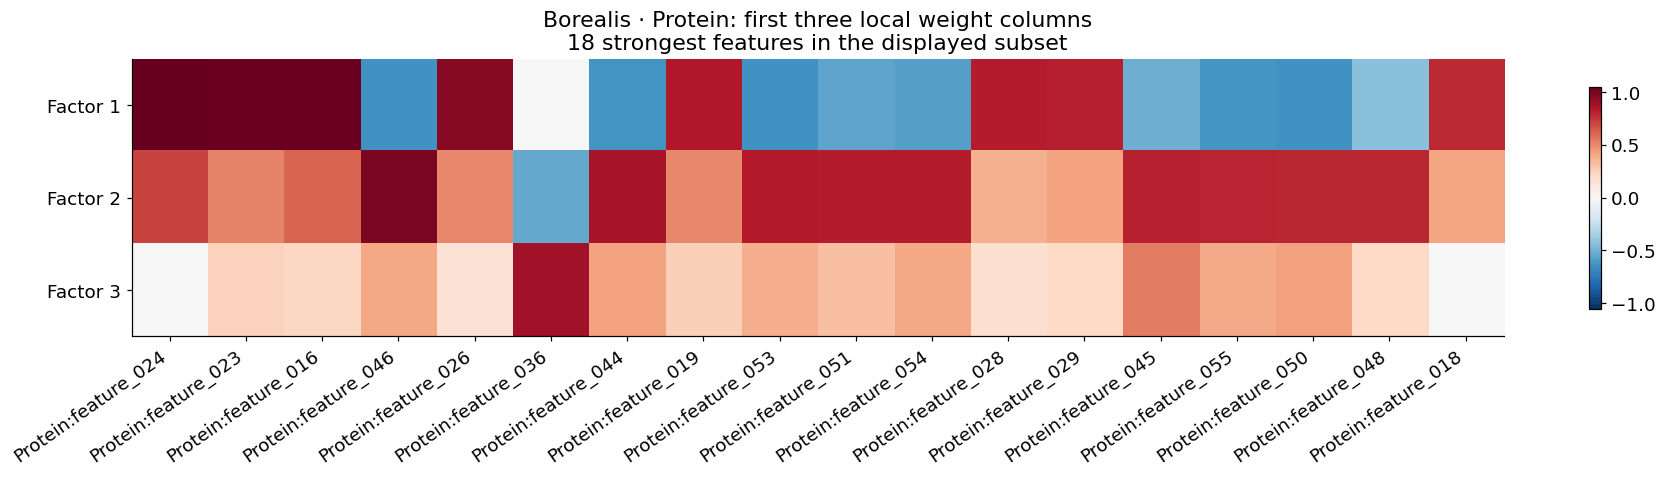

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, ((g, v), z) in zip(axes.flat, scores.items()):
    obs = data[g][v].obs
    for label in ['Healthy', 'Diseased']:
        mask = obs.disease.eq(label)
        ax.scatter(z.loc[mask].iloc[:, 0], z.loc[mask].iloc[:, 1], label=label, s=20)
    ax.set(title=f'{g} · {v}', xlabel=z.columns[0], ylabel=z.columns[1]); ax.legend()
fig.tight_layout(); plt.show()
for (g, v), w in weights.items():
    weights_plot(w.iloc[:, :3], f'{g} · {v}: first three local weight columns')

### Summarise reconstruction and disease association separately

For each **independent fit**, `get_r2(type='total')` measures reconstruction of its observed table. `disease_association` aligns metadata to score rows, encodes disease status as 0/1 and computes absolute score–disease correlations. The largest correlation identifies a locally disease-associated axis; its factor name is not transferable to another model.

This table is descriptive. Disease labels did not guide fitting, high reconstruction R² need not imply disease relevance, and the maximum of several correlations is not a calibrated significance test.

In [9]:
summary = []
for (g, v), model in models.items():
    assoc = disease_association(scores[g, v], data[g][v].obs)
    summary.append(dict(planet=g, view=v, total_R2=model.get_r2(type='total').R2.iloc[0],
                        disease_axis=assoc.idxmax(), abs_disease_correlation=assoc.max(),
                        epochs=len(model.training_loss)))
display(pd.DataFrame(summary).round(3))

,planet,view,total_R2,disease_axis,abs_disease_correlation,epochs
0,Asteron,RNA,0.879,Factor 4,0.822,1200
1,Asteron,Protein,0.685,Factor 3,0.759,1011
2,Borealis,RNA,0.878,Factor 5,0.765,843
3,Borealis,Protein,0.696,Factor 4,0.770,1200


## Compare sample scores within planets and feature weights across planets

We are comparing the **four already fitted independent models**, not fitting an integrated model. The next cell deliberately makes two kinds of comparison.

First, `crosscorr(scores[g, 'RNA'], scores[g, 'Protein'])` matches rows by inhabitant ID within a planet and correlates every RNA score column with every protein score column. Second, `crosscorr(wa, wb)` matches rows by feature ID within one modality and compares weight patterns across planets. The helper's row alignment makes the meaning of its inputs crucial: matching people for the first calculation, matching features for the second. `.abs()` accommodates sign changes, while off-diagonal matches may reflect reordered factors. `heatmap` draws the resulting correlation tables; it does not align or refit the models.

`subspace_similarity(wa, wb)` centres the matched feature-weight tables and compares the spaces their columns span. Near 1 indicates similar spaces despite sign, order or rotations. It does not prove that every factor has a unique counterpart or that the biology is conserved.

**Predict:** in which comparison are the matched rows people, and in which are they molecular features?

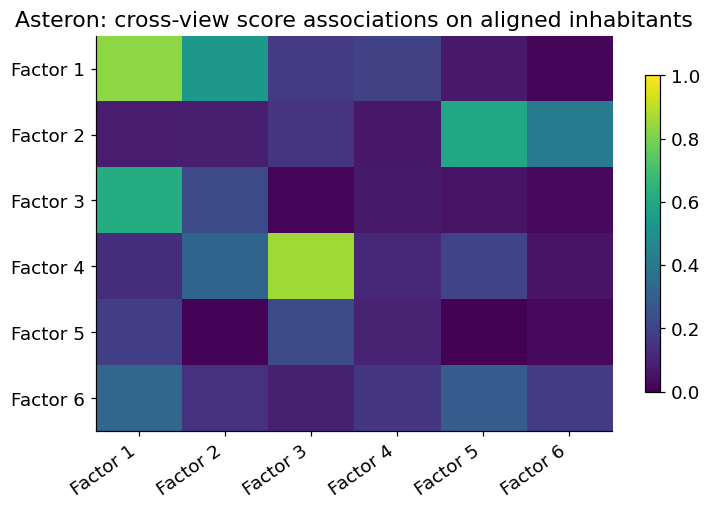

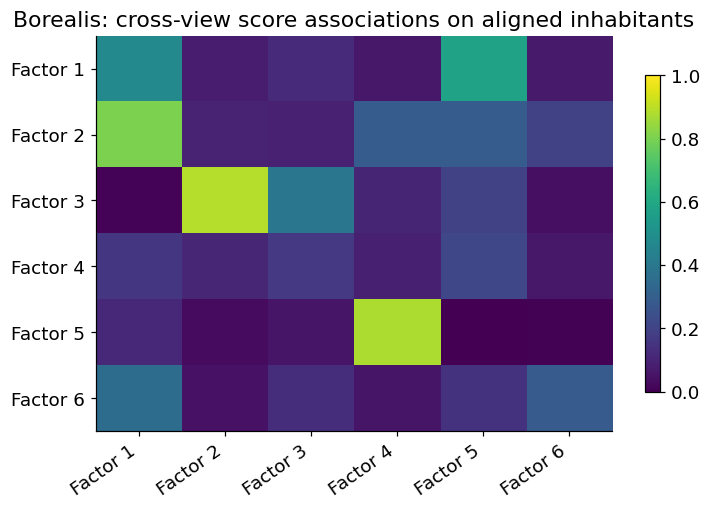

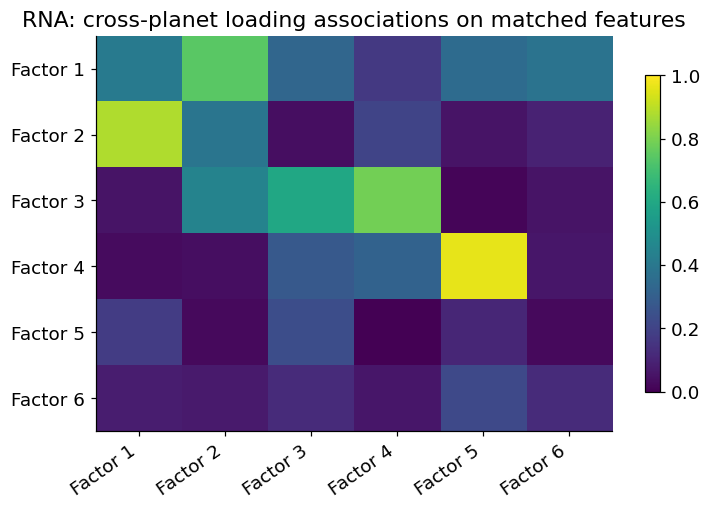

RNA loading-subspace similarity: 0.661


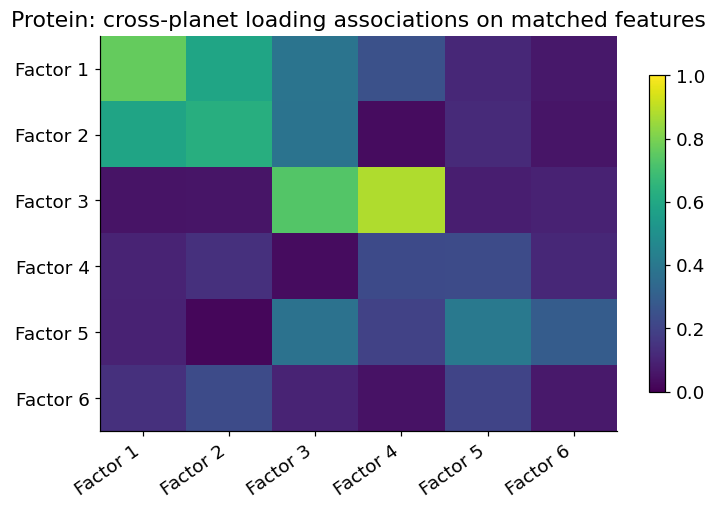

Protein loading-subspace similarity: 0.541


In [10]:
for g in SPEC['samples']:
    heatmap(crosscorr(scores[g, 'RNA'], scores[g, 'Protein']).abs(),
            f'{g}: cross-view score associations on aligned inhabitants', vmin=0, vmax=1)
for v in SPEC['features']:
    wa, wb = weights['Asteron', v], weights['Borealis', v]
    heatmap(crosscorr(wa, wb).abs(), f'{v}: cross-planet loading associations on matched features', vmin=0, vmax=1)
    print(v, 'loading-subspace similarity:', round(subspace_similarity(wa, wb), 3))

### Ask what each independent score space contains

Only now does `load_truth()` reveal the saved activities for evaluation. `truth_projection(z, teacher['scores'][g])` matches the relevant planet's inhabitants, centres both tables and fits a least-squares combination of that model's score columns to each true activity. It reports training activity-recovery R²; it does not change the **four fitted omics models**.

`heatmap` compares these diagnostic values across the four representations. A high value can coexist with mixed individual axes. A small accidental value for an unmeasured process is not proof that a modality recovered it, especially with several fitted columns and finite samples.

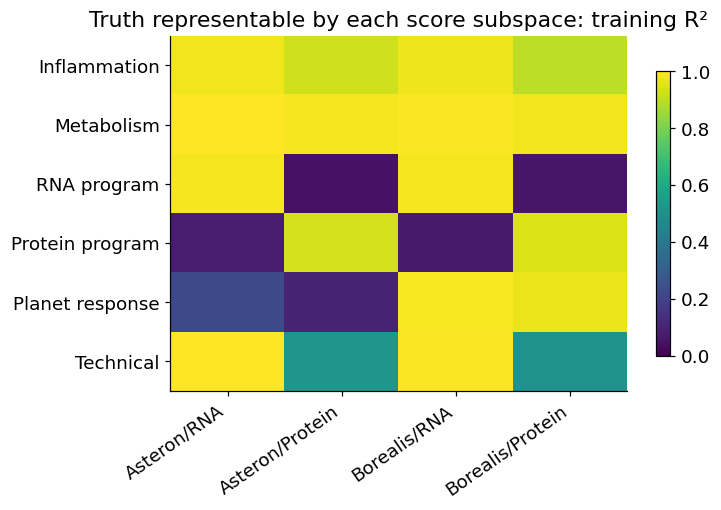

In [11]:
teacher = load_truth()
recovery = pd.DataFrame({f'{g}/{v}': truth_projection(z, teacher['scores'][g])
                         for (g, v), z in scores.items()})
heatmap(recovery, 'Truth representable by each score subspace: training R²', vmin=0, vmax=1)

## Why do independent analyses leave a question open?

Each **independent planet–view model** gives a local representation. A differing factor sign, number or orientation is not itself a biological difference. Modality sensitivity, measurement noise, separate preprocessing and real activity differences can also affect the results. A high disease association does not establish a common mechanism, and a weak association does not establish absent biology.

What have we been able to compare? Matched inhabitants support score comparisons across views within a planet; matched feature identifiers support weight comparisons across planets within a view. No paired sample-score comparison is available between planets.

**Next we fit Asteron RNA and protein jointly**, so the same inhabitants have one sample coordinate system. After that we ask whether different inhabitants on the two planets can be described using shared feature patterns.

For optional exploration, try matching independent columns by sign and permutation, then ask whether remaining differences still require mixtures of axes.